In [85]:
# Run once. Installs any missing packages into this notebook's kernel.
%pip install --quiet pandas numpy seaborn matplotlib plotly ipython
print('Packages ready. If anything was just installed, restart the kernel and continue.')

You should consider upgrading via the '/Users/imc/Documents/cs2410/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Packages ready. If anything was just installed, restart the kernel and continue.


In [86]:
# Import packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Slide "Words of warning: Colors": avoid red-vs-green as the only distinguishing feature.
# seaborn's 'colorblind' palette is safe for the most common color-vision deficiency (CVD).
sns.set_palette('colorblind')
sns.set_theme(style='whitegrid', palette='colorblind')

pd.set_option('display.max_columns', 30)

In [87]:
# ============================================================
#  EDA TOOLKIT  (each function maps to a slide in the lecture)
# ============================================================

def feature_type(series):
    """
    Slide: "Step 1: Understand the data — identify and categorize the features".
    Returns 'numerical' or 'categorical' for a pandas Series.
    A column of numbers with very few distinct values (e.g. 0/1 flags) is
    treated as categorical, because a histogram of it would be meaningless.
    """
    if pd.api.types.is_numeric_dtype(series):
        if series.nunique() <= 5:          # e.g. a 0/1 flag or a 1-5 rating
            return 'categorical'
        return 'numerical'
    return 'categorical'


def feature_table(df):
    """
    Slide: "Exploratory Data Analysis in Python" (df.shape / df.info()).
    One row per column: our type label, pandas dtype, # non-null, # missing, # unique.
    This is df.info() rearranged into a DataFrame you can sort and filter.
    """
    rows = []
    for col in df.columns:
        s = df[col]
        rows.append({'feature': col,
                     'type': feature_type(s),
                     'dtype': str(s.dtype),
                     'non_null': s.notna().sum(),
                     'missing': s.isna().sum(),
                     'unique': s.nunique()})
    return pd.DataFrame(rows).set_index('feature')


def missing_report(df):
    """
    Slide: "Missing Data". Count and percent of missing values per column,
    sorted so the worst column is on top. Columns with nothing missing are dropped.
    """
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(1)
    out = pd.DataFrame({'missing': miss, 'percent': pct})
    return out[out['missing'] > 0].sort_values('missing', ascending=False)


def five_number_summary(series):
    """
    Slide: "Box plot — a visual representation of the five-number summary".
    Returns min, Q1, median, Q3, max as a Series. This is exactly what a box plot draws.
    """
    q1, med, q3 = series.quantile([0.25, 0.5, 0.75])
    return pd.Series({'min': series.min(), 'Q1': q1, 'median': med,
                      'Q3': q3, 'max': series.max(), 'IQR': q3 - q1})


def describe_shape(series):
    """
    Slide: "Step 3: Describe the shape of data — symmetric or skewed".
    Uses the skewness statistic. Rule of thumb used in this course:
        |skew| < 0.5   -> 'approximately symmetric'
        0.5..1         -> 'moderately skewed'
        > 1            -> 'highly skewed'
    The sign tells the direction: positive = long right tail, negative = long left tail.
    """
    sk = series.dropna().skew()
    direction = 'right (positive)' if sk > 0 else 'left (negative)'
    if abs(sk) < 0.5:
        label = 'approximately symmetric'
    elif abs(sk) < 1:
        label = f'moderately skewed to the {direction}'
    else:
        label = f'highly skewed to the {direction}'
    return {'skewness': round(sk, 3), 'shape': label}


def plot_one_feature(df, col, ax=None):
    """
    Slide: "Guidelines for selecting plots" — the level of measurement decides the plot.
      categorical -> countplot (bar chart of counts)
      numerical   -> histogram with a density curve on top
    Returns the Axes so you can keep customizing it.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    if feature_type(df[col]) == 'categorical':
        sns.countplot(data=df, x=col, ax=ax)
        ax.set_ylabel('Count')
    else:
        sns.histplot(data=df, x=col, kde=True, ax=ax)
        ax.set_ylabel('Frequency')
    ax.set_title(f'Distribution of {col}')
    return ax


def strength_label(r):
    """
    Slide: "Step 2: Identify relationships — direction and strength of correlation".
    Converts a correlation coefficient into words (course rule of thumb).
    """
    direction = 'positive' if r > 0 else 'negative'
    a = abs(r)
    if a >= 0.7:
        strength = 'strong'
    elif a >= 0.4:
        strength = 'moderate'
    elif a >= 0.2:
        strength = 'weak'
    else:
        return 'no meaningful linear relationship'
    return f'{strength} {direction}'


def correlation_pairs(df, top=10):
    """
    Slide: "Identifying relationships between features".
    Lists every pair of numerical features with its correlation and a plain-English label,
    strongest first. Much easier to read than staring at a full correlation matrix.
    """
    corr = df.corr(numeric_only=True)
    pairs = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr.iloc[i, j]
            pairs.append({'feature_1': cols[i], 'feature_2': cols[j],
                          'r': round(r, 3), 'relationship': strength_label(r)})
    out = pd.DataFrame(pairs)
    return out.reindex(out['r'].abs().sort_values(ascending=False).index).head(top).reset_index(drop=True)


print('Toolkit loaded:', ', '.join(['feature_type', 'feature_table', 'missing_report',
      'five_number_summary', 'describe_shape', 'plot_one_feature', 'strength_label', 'correlation_pairs']))

Toolkit loaded: feature_type, feature_table, missing_report, five_number_summary, describe_shape, plot_one_feature, strength_label, correlation_pairs


In [88]:
# Load outcome dataset

numeric_cols_oc_hs = ["Regular HS Diploma Graduates (Count)",
       "Regular HS Diploma Graduates (Rate)", "Met UC/CSU Grad Reqs (Count)",
       "Met UC/CSU Grad Reqs (Rate)", "Seal of Biliteracy (Count)",
       "Seal of Biliteracy (Rate)", "Golden State Seal Merit Diploma (Count)",
       "Golden State Seal Merit Diploma (Rate", "CHSPE Completer (Count)",
       "CHSPE Completer (Rate)", "Adult Ed. HS Diploma (Count)",
       "Adult Ed. HS Diploma (Rate)", "SPED Certificate (Count)",
       "SPED Certificate (Rate)", "GED Completer (Count)",
       "GED Completer (Rate)", "Other Transfer (Count)",
       "Other Transfer (Rate)", "Dropout (Count)", "Dropout (Rate)",
       "Still Enrolled (Count)", "Still Enrolled (Rate)"]
NUMBER_OC_HS = [np.float32 for x in numeric_cols_oc_hs]
hs_outcomes_dtypes = dict(zip(numeric_cols_oc_hs, NUMBER_OC_HS))
# I used AI to remove the whitespace from the CSV that I had a VSCode extension add
# oops lol
hs_outcomes = pd.read_csv('acgr23-v2.csv',
                       dtype=hs_outcomes_dtypes,
                       na_values=["NA", "", "NaN", "*"],
                       skipinitialspace=True,
                       )

In [89]:
# Load other outcome dataset (college instead of just hs)

integer_cols_oc_college16 = ['High School Completers',
       'Enrolled In College - Total (16 Months)',
       'College Going Rate - Total (16 Months)',
       'Enrolled In-State (16 Months)', 'Enrolled Out-of-State (16 Months)',
       'Not Enrolled In College (16 Months)', 'Enrolled UC (16 Months)',
       'Enrolled CSU (16 Months)', 'Enrolled CCC (16 Months)',
       'Enrolled In-State Private (2 and 4 Year) (16 Months)',
       'Enrolled Out-of-State 4-Year College (Public/Private) (16 Months)',
       'Enrolled Out-of-State 2-Year College (Public/Private) (16 Months)']
INTEGER_OC_COLLEGE = [np.int32 for x in integer_cols_oc_college16]
college16_outcomes_dtypes = dict(zip(integer_cols_oc_college16, INTEGER_OC_COLLEGE))

# I used AI to convert the TSV into a CSV.
college_16mo_outcomes = pd.read_csv('cgr16mo23.csv',
                               na_values=["NA", "", "NaN", "*"],
                               skipinitialspace=True
                               )

college_16mo_outcomes.dropna(how='any', subset=integer_cols_oc_college16, inplace=True)
college_16mo_outcomes = college_16mo_outcomes.convert_dtypes()
college_16mo_outcomes.dtypes

AcademicYear                                                         string[python]
AggregateLevel                                                       string[python]
CountyCode                                                                    Int64
DistrictCode                                                                  Int64
SchoolCode                                                                    Int64
CountyName                                                           string[python]
DistrictName                                                         string[python]
SchoolName                                                           string[python]
CharterSchool                                                        string[python]
AlternativeSchoolAccountabilityStatus                                string[python]
ReportingCategory                                                    string[python]
CompleterType                                                        string[

In [104]:
integer_cols_oc_college12 = ['High School Completers',
       'Enrolled In College - Total (12 Months)',
       'College Going Rate - Total (12 Months)',
       'Enrolled In-State (12 Months)', 'Enrolled Out-of-State (12 Months)',
       'Not Enrolled In College (12 Months)', 'Enrolled UC (12 Months)',
       'Enrolled CSU (12 Months)', 'Enrolled CCC (12 Months)',
       'Enrolled In-State Private (2 and 4 Year) (12 Months)',
       'Enrolled Out-of-State 4-Year College (Public/Private) (12 Months)',
       'Enrolled Out-of-State 2-Year College (Public/Private) (12 Months)']
college16_outcomes_dtypes = dict(zip(integer_cols_oc_college12, INTEGER_OC_COLLEGE))

college_12mo_outcomes = pd.read_csv('cgr12mo23.csv',
                               na_values=["NA", "", "NaN", "*"],
                               skipinitialspace=True
                               )
college_12mo_outcomes.set_index("DistrictCode")

college_12mo_outcomes.dropna(how='any', subset=integer_cols_oc_college12, inplace=True)
college_12mo_outcomes = college_12mo_outcomes.convert_dtypes()
college_12mo_outcomes.dtypes

AcademicYear                                                         string[python]
AggregateLevel                                                       string[python]
CountyCode                                                                    Int64
DistrictCode                                                                  Int64
SchoolCode                                                                    Int64
CountyName                                                           string[python]
DistrictName                                                         string[python]
SchoolName                                                           string[python]
CharterSchool                                                        string[python]
AlternativeSchoolAccountabilityStatus                                string[python]
ReportingCategory                                                    string[python]
CompleterType                                                        string[

In [105]:
college_outcomes = pd.merge( college_16mo_outcomes, college_12mo_outcomes)
outcomes = pd.merge(hs_outcomes, college_outcomes)
outcomes

,AcademicYear,AggregateLevel,CountyCode,DistrictCode,SchoolCode,CountyName,DistrictName,SchoolName,CharterSchool,DASS,ReportingCategory,CohortStudents,Regular HS Diploma Graduates (Count),Regular HS Diploma Graduates (Rate),Met UC/CSU Grad Reqs (Count),...,Enrolled CCC (16 Months),Enrolled In-State Private (2 and 4 Year) (16 Months),Enrolled Out-of-State 4-Year College (Public/Private) (16 Months),Enrolled Out-of-State 2-Year College (Public/Private) (16 Months),Enrolled In College - Total (12 Months),College Going Rate - Total (12 Months),Enrolled In-State (12 Months),Enrolled Out-of-State (12 Months),Not Enrolled In College (12 Months),Enrolled UC (12 Months),Enrolled CSU (12 Months),Enrolled CCC (12 Months),Enrolled In-State Private (2 and 4 Year) (12 Months),Enrolled Out-of-State 4-Year College (Public/Private) (12 Months),Enrolled Out-of-State 2-Year College (Public/Private) (12 Months)
0,2022-23,T,0,NaN,NaN,State,NaN,NaN,All,All,GM,253704.0,213044.0,84.000000,100419.0,...,398,4,3,6,390,57.1,383,7,293,1,1,378,3,2,5
1,2022-23,T,0,NaN,NaN,State,NaN,NaN,All,All,GM,253704.0,213044.0,84.000000,100419.0,...,4713,301,227,172,4818,21.6,4485,333,17517,8,36,4217,224,189,144
2,2022-23,T,0,NaN,NaN,State,NaN,NaN,All,All,GM,253704.0,213044.0,84.000000,100419.0,...,46977,1799,2266,901,50591,42.4,47836,2755,68772,636,1930,43784,1486,2041,714
3,2022-23,T,0,NaN,NaN,State,NaN,NaN,All,All,GM,253704.0,213044.0,84.000000,100419.0,...,33237,4060,10231,336,82965,82.4,72693,10272,17769,13939,22863,32006,3885,9997,275
4,2022-23,T,0,NaN,NaN,State,NaN,NaN,All,All,GM,253704.0,213044.0,84.000000,100419.0,...,486,8,5,14,476,41.8,461,15,664,1,1,453,6,4,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139201,2022-23,C,58,NaN,NaN,Yuba,NaN,NaN,Yes,Yes,TA,61.0,21.0,34.400002,0.0,...,19,0,3,0,27,79.4,24,3,7,2,3,19,0,3,0
139202,2022-23,C,58,NaN,NaN,Yuba,NaN,NaN,Yes,Yes,TA,61.0,21.0,34.400002,0.0,...,5,0,0,0,4,17.4,4,0,19,0,0,4,0,0,0
139203,2022-23,C,58,NaN,NaN,Yuba,NaN,NaN,Yes,Yes,TA,61.0,21.0,34.400002,0.0,...,54,0,5,0,64,52.9,59,5,57,2,6,51,0,5,0
139204,2022-23,C,58,NaN,NaN,Yuba,NaN,NaN,Yes,Yes,TA,61.0,21.0,34.400002,0.0,...,5,0,0,0,4,17.4,4,0,19,0,0,4,0,0,0


In [98]:
# Remove useless columns
outcomes.drop(columns=["AcademicYear"], inplace=True)


# Remove useless rows that don't have any useful data, and then narrow the data types
outcomes.dropna(how="all", subset=numeric_cols_oc_hs, inplace=True)
outcomes.dropna(how="any", subset=["DistrictCode", "SchoolCode"], inplace=True)
outcomes = outcomes.convert_dtypes()
# (this cuts the rows from 139k to 104k so uhh not the worst!)
outcomes

,AggregateLevel,CountyCode,DistrictCode,SchoolCode,CountyName,DistrictName,SchoolName,CharterSchool,DASS,ReportingCategory,CohortStudents,Regular HS Diploma Graduates (Count),Regular HS Diploma Graduates (Rate),Met UC/CSU Grad Reqs (Count),Met UC/CSU Grad Reqs (Rate),...,Enrolled CCC (16 Months),Enrolled In-State Private (2 and 4 Year) (16 Months),Enrolled Out-of-State 4-Year College (Public/Private) (16 Months),Enrolled Out-of-State 2-Year College (Public/Private) (16 Months),Enrolled In College - Total (12 Months),College Going Rate - Total (12 Months),Enrolled In-State (12 Months),Enrolled Out-of-State (12 Months),Not Enrolled In College (12 Months),Enrolled UC (12 Months),Enrolled CSU (12 Months),Enrolled CCC (12 Months),Enrolled In-State Private (2 and 4 Year) (12 Months),Enrolled Out-of-State 4-Year College (Public/Private) (12 Months),Enrolled Out-of-State 2-Year College (Public/Private) (12 Months)
1209,S,1,10017,112607,Alameda,Alameda County Office of Education,Envision Academy for Arts & Technology,Yes,No,GF,39,33,84.599998,31,93.900002,...,7,1,3,0,22,66.7,19,3,11,4,8,7,0,3,0
1210,S,1,10017,112607,Alameda,Alameda County Office of Education,Envision Academy for Arts & Technology,Yes,No,GF,39,33,84.599998,31,93.900002,...,7,1,3,0,22,71.0,19,3,9,4,8,7,0,3,0
1211,S,1,10017,112607,Alameda,Alameda County Office of Education,Envision Academy for Arts & Technology,Yes,No,GM,34,29,85.300003,29,100.0,...,3,1,3,0,17,56.7,14,3,13,3,8,2,1,3,0
1212,S,1,10017,112607,Alameda,Alameda County Office of Education,Envision Academy for Arts & Technology,Yes,No,GM,34,29,85.300003,29,100.0,...,3,1,3,0,17,56.7,14,3,13,3,8,2,1,3,0
1213,S,1,10017,112607,Alameda,Alameda County Office of Education,Envision Academy for Arts & Technology,Yes,No,RB,27,23,85.199997,22,95.699997,...,4,1,4,0,16,69.6,12,4,7,4,4,3,1,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113355,D,58,72769,0,Yuba,Wheatland Union High,District Office,All,Yes,TA,35,30,85.699997,0,0.0,...,4,0,0,1,5,16.1,4,1,26,0,0,4,0,0,1
113356,D,58,72769,0,Yuba,Wheatland Union High,District Office,All,Yes,TA,35,30,85.699997,0,0.0,...,4,0,0,1,5,16.1,4,1,26,0,0,4,0,0,1
113357,D,58,72769,0,Yuba,Wheatland Union High,District Office,All,Yes,TA,35,30,85.699997,0,0.0,...,56,1,3,3,65,41.4,59,6,92,2,2,54,1,3,3
113358,D,58,72769,0,Yuba,Wheatland Union High,District Office,All,Yes,TA,35,30,85.699997,0,0.0,...,47,1,7,1,74,76.3,67,7,23,8,13,44,2,7,0


In [ ]:
cdcodes_outcomes = outcomes["DistrictCode"].copy().drop_duplicates()
cdcodes_stex = stex["DistrictCode"].copy()
cdcodes_merged = pd.merge(cdcodes_outcomes, cdcodes_stex)
# cdcodes_transfers
cdcodes_merged.drop_duplicates()

,DistrictCode
0,10017
516,61119
1167,61176
2131,61192
3009,61259
...,...
244847,73874
245229,76828
245645,72686
245940,72710


*`AI was used about here, so I could determine what the more opauqe columns, like 'reporting category', meant`*

ChatGPT cited this page: https://www.cde.ca.gov/ds/ad/fsoygrads.asp so I extrapolated that its terms also applied to the ACGR dataset.

Update later on: Yeah I'm blind. There's literally "file structure" links to the right of the download links that explains what everything is. WHATEVER MAN lol

In [106]:
# aggregate outcomes using total numbers per-district
count_cols_oc = [col for col in outcomes.columns if "(Count)" in col]
count_cols_oc += integer_cols_oc_college16 + integer_cols_oc_college12
count_cols_oc.append("CohortStudents")

rate_cols_oc = [col for col in outcomes.columns if "rate" in col.lower()]

name_cols_oc = ["DistrictName"]

SUM_COUNTS_OC = ["sum" for x in count_cols_oc]
MEAN_RATES_OC = ["mean" for x in rate_cols_oc]
MODE_NAMES_OC = [pd.Series.mode for x in name_cols_oc]

sum_oc = dict(zip(count_cols_oc, SUM_COUNTS_OC))
mean_oc = dict(zip(rate_cols_oc, MEAN_RATES_OC))
mode_oc = dict(zip(name_cols_oc, MODE_NAMES_OC))

agg_oc = mode_oc | sum_oc | mean_oc

outcomes_total = outcomes.loc[(outcomes["ReportingCategory"] == "TA")
                              & (outcomes["DistrictCode"] != 0) # probably unnecessary since i changed the dropna call but #whatevs
                              ]
# outcomes_total_district = outcomes_total.aggregate()


outcomes_aggregation = outcomes_total.groupby("DistrictCode").agg(agg_oc)
outcomes_aggregation


,DistrictName,Regular HS Diploma Graduates (Count),Met UC/CSU Grad Reqs (Count),Seal of Biliteracy (Count),Golden State Seal Merit Diploma (Count),CHSPE Completer (Count),Adult Ed. HS Diploma (Count),SPED Certificate (Count),GED Completer (Count),Other Transfer (Count),Dropout (Count),Still Enrolled (Count),High School Completers,Enrolled In College - Total (16 Months),College Going Rate - Total (16 Months),...,Enrolled In-State Private (2 and 4 Year) (12 Months),Enrolled Out-of-State 4-Year College (Public/Private) (12 Months),Enrolled Out-of-State 2-Year College (Public/Private) (12 Months),CohortStudents,Regular HS Diploma Graduates (Rate),Met UC/CSU Grad Reqs (Rate),Seal of Biliteracy (Rate),Golden State Seal Merit Diploma (Rate,CHSPE Completer (Rate),Adult Ed. HS Diploma (Rate),SPED Certificate (Rate),GED Completer (Rate),Other Transfer (Rate),Dropout (Rate),Still Enrolled (Rate)
DistrictCode,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10017.0,Alameda County Office of Education,8276.0,3333.0,0.0,467.0,39.0,0.0,0.0,0.0,156.0,2746.0,1660.0,8496,3506,48.979687,...,182,336,26,12877.0,70.051559,43.895313,0.000000,6.987500,0.515625,0.0,0.000000,0.000000,1.190625,18.551563,9.732813
10041.0,Butte County Office of Education,4444.0,1155.0,35.0,1400.0,0.0,0.0,70.0,68.0,0.0,766.0,1000.0,3816,2311,62.383636,...,26,130,0,6348.0,67.914543,19.389091,0.578182,23.496365,0.000000,0.0,1.010909,1.170909,0.000000,12.787272,17.130909
10058.0,Calaveras County Office of Education,818.0,72.0,0.0,180.0,0.0,0.0,0.0,0.0,18.0,26.0,4.0,959,304,31.45,...,0,22,0,866.0,94.522217,8.811110,0.000000,22.000000,0.000000,0.0,0.000000,0.000000,2.055556,2.922222,0.422222
10074.0,Contra Costa County Office of Education,22664.0,21660.0,1140.0,10890.0,90.0,0.0,176.0,0.0,0.0,1208.0,350.0,20144,16353,59.728846,...,676,1846,104,24488.0,81.340385,69.284615,3.401923,32.473076,0.373077,0.0,1.238462,0.000000,0.000000,14.948076,2.113461
10082.0,Del Norte County Office of Education,936.0,0.0,0.0,90.0,0.0,0.0,18.0,0.0,8.0,324.0,0.0,1576,330,20.936364,...,0,22,0,1286.0,69.745453,0.000000,0.000000,8.218182,0.000000,0.0,1.236364,0.000000,1.181818,27.836365,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77198.0,SBE - Olive Grove Charter - Orcutt/Santa Maria,468.0,36.0,0.0,72.0,0.0,0.0,0.0,0.0,18.0,162.0,126.0,459,162,35.15,...,0,9,0,774.0,60.500000,7.699999,0.000000,15.399999,0.000000,0.0,0.000000,0.000000,2.300000,20.900000,16.299999
77206.0,SBE - Olive Grove Charter - Lompoc,180.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0,126.0,126.0,216,72,33.3,...,0,0,0,432.0,41.700001,0.000000,0.000000,20.000000,0.000000,0.0,0.000000,0.000000,0.000000,29.200003,29.200003
77222.0,SBE - Olive Grove Charter - Santa Barbara,396.0,36.0,0.0,18.0,0.0,0.0,0.0,0.0,0.0,108.0,72.0,387,216,55.8,...,18,0,0,576.0,68.800003,9.100000,0.000000,4.500000,0.000000,0.0,0.000000,0.000000,0.000000,18.799999,12.500000


In [102]:
OUTCOME = "College Going Rate - Total (16 Months)"
EXPLANATORY = ["Average Total Years Experience", "Average District Years Experience", "Total Staff Count"]

def viability_report(df, outcome, explanatory, min_rows=200, min_cols=8):
    print(f"1. Opened: yes — {df.shape[0]} rows x {df.shape[1]} columns")
    print(f"2. Big enough? rows >= {min_rows}: {df.shape[0] >= min_rows} | columns >= {min_cols}: {df.shape[1] >= min_cols}")
    missing = [c for c in [outcome] + explanatory if c not in df.columns]
    print(f"3. Columns exist? {'yes' if not missing else 'MISSING: ' + str(missing)}")
    pct = (df[[outcome] + [c for c in explanatory if c in df.columns]].isna().mean() * 100).round(1)
    print("4. % missing in the columns that matter:")
    print(pct.to_string())
    print("5. Source: (write one sentence about who collected it, when, how)")
    print(f"6. Messy? duplicates={df.duplicated().sum()}, any impossible values? -> check describe() above")
    print("7. Anything you shouldn't have? (names, personal data, terms of use)")

viability_report(outcomes_aggregation, OUTCOME, EXPLANATORY)

1. Opened: yes — 520 rows x 37 columns
2. Big enough? rows >= 200: True | columns >= 8: True
3. Columns exist? MISSING: ['Average Total Years Experience', 'Average District Years Experience', 'Total Staff Count']
4. % missing in the columns that matter:
College Going Rate - Total (16 Months)    0.0
5. Source: (write one sentence about who collected it, when, how)
6. Messy? duplicates=0, any impossible values? -> check describe() above
7. Anything you shouldn't have? (names, personal data, terms of use)


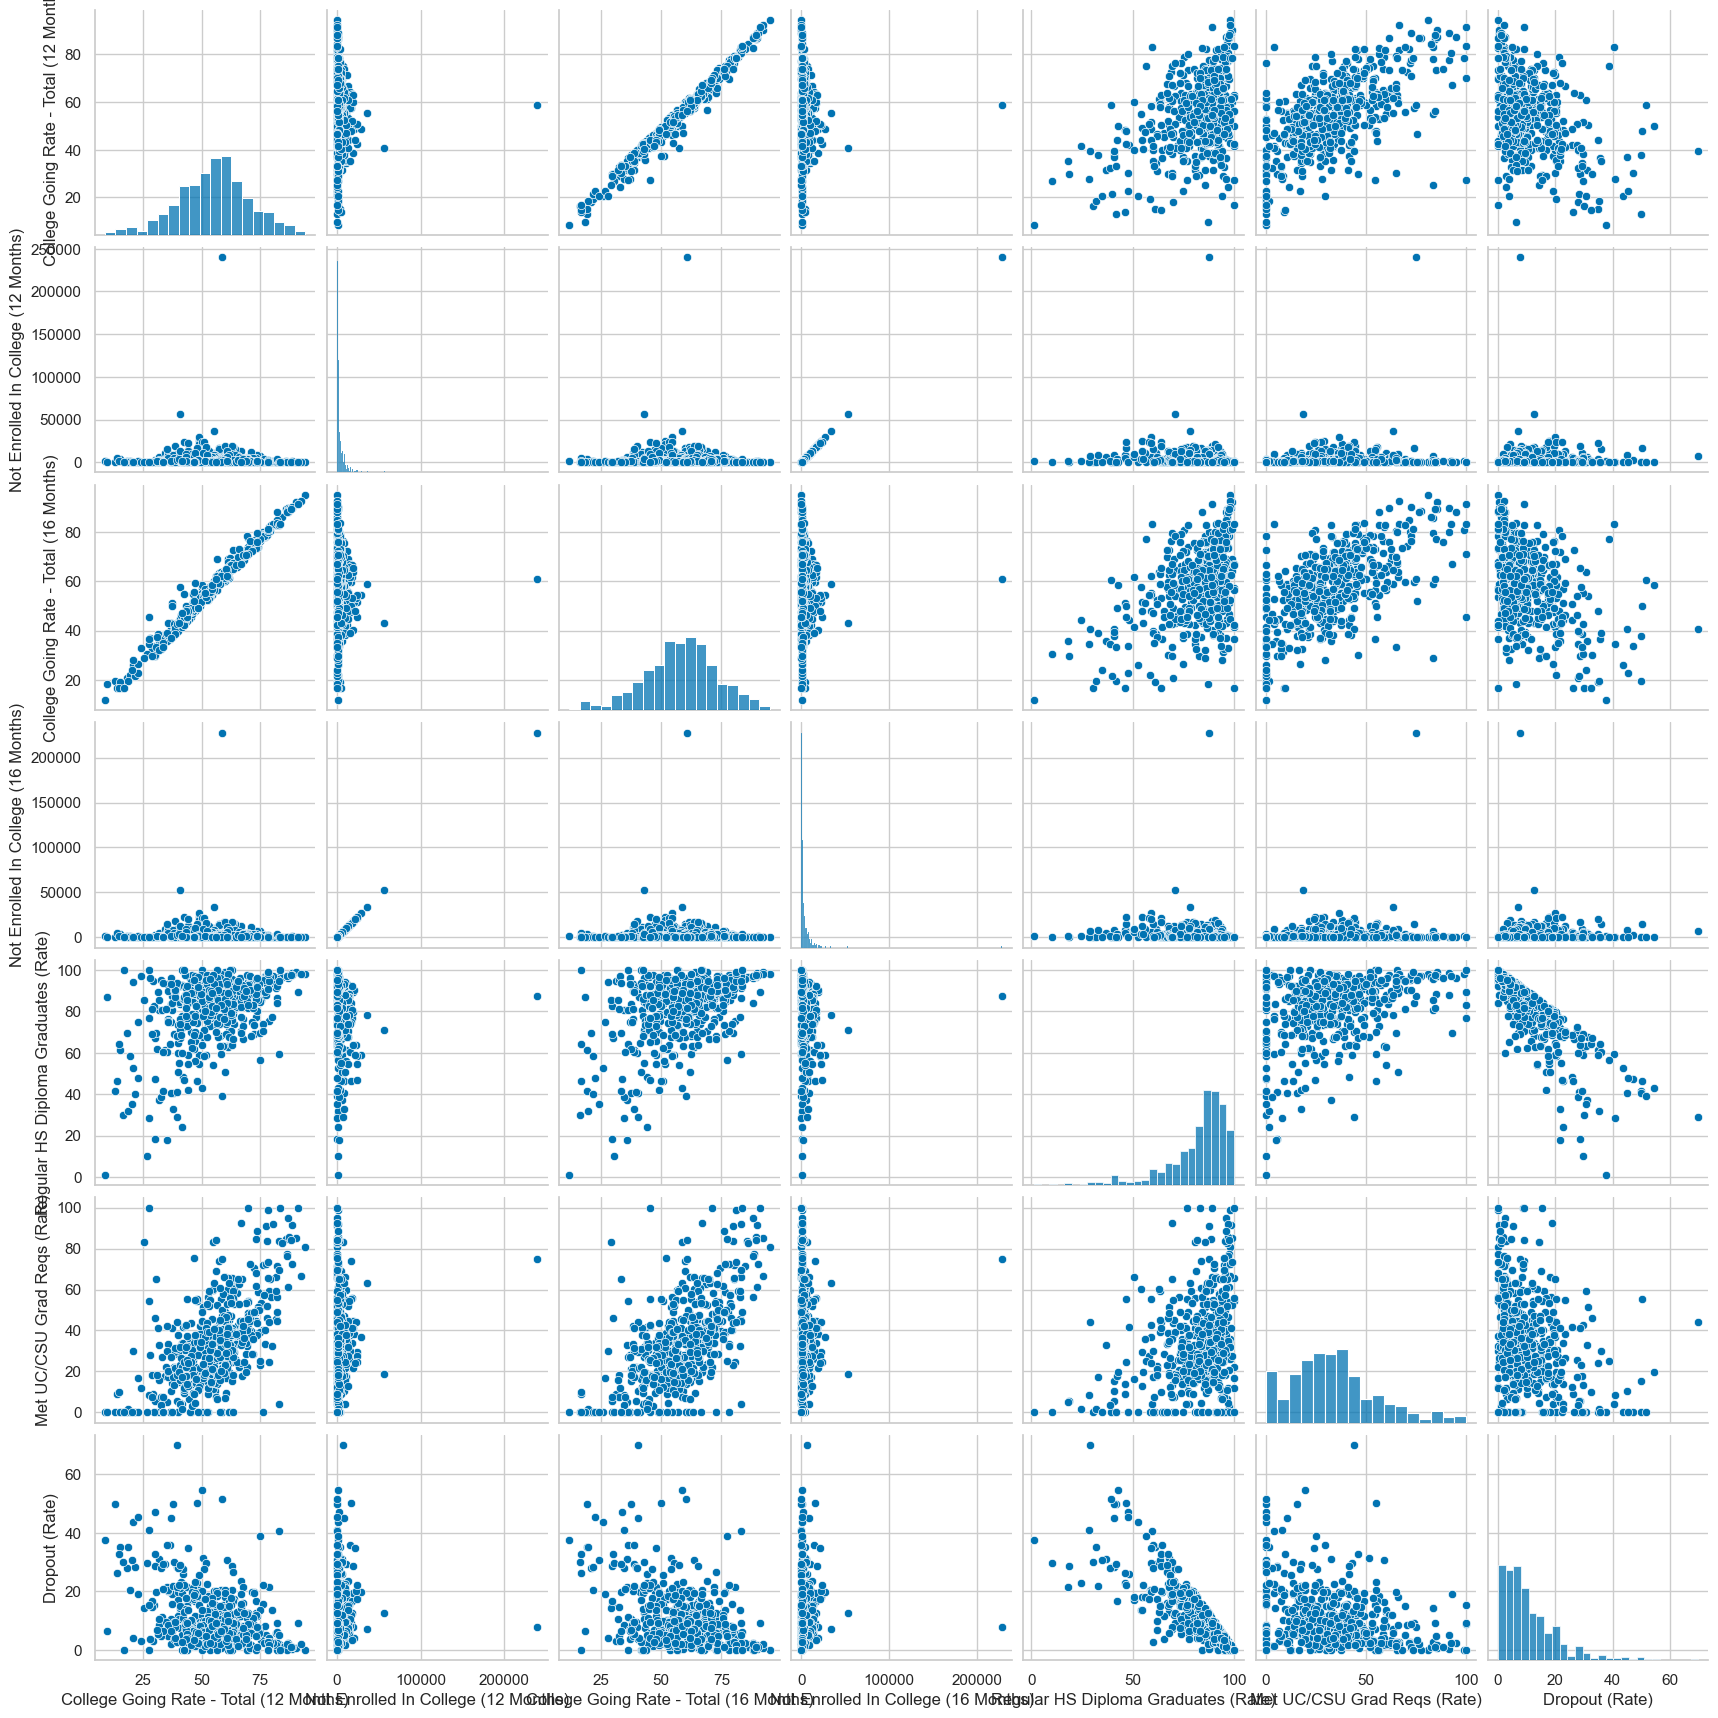

In [107]:
# LAUSD has nearly 500k staff, rest have much less.
# most have under 50k
# data_to_plot = outcomes_aggregation[outcomes_and_stex["Total Staff Count"] < 50_000] 

cols_to_plot = [
                    "College Going Rate - Total (12 Months)", "Not Enrolled In College (12 Months)", 
                    "College Going Rate - Total (16 Months)", "Not Enrolled In College (16 Months)", 
                    "Regular HS Diploma Graduates (Rate)", "Met UC/CSU Grad Reqs (Rate)", "Dropout (Rate)",

                    
                ]

sns.pairplot(outcomes_aggregation[cols_to_plot], )



In [111]:
outcomes_aggregation[cols_to_plot].corr(numeric_only=True)

,College Going Rate - Total (12 Months),Not Enrolled In College (12 Months),College Going Rate - Total (16 Months),Not Enrolled In College (16 Months),Regular HS Diploma Graduates (Rate),Met UC/CSU Grad Reqs (Rate),Dropout (Rate)
College Going Rate - Total (12 Months),1.000000,-0.032661,0.989438,-0.036146,0.457187,0.606741,-0.422521
Not Enrolled In College (12 Months),-0.032661,1.000000,-0.035420,0.999880,-0.066589,0.098950,0.043826
College Going Rate - Total (16 Months),0.989438,-0.035420,1.000000,-0.039381,0.460405,0.617377,-0.421295
Not Enrolled In College (16 Months),-0.036146,0.999880,-0.039381,1.000000,-0.066711,0.095783,0.044422
Regular HS Diploma Graduates (Rate),0.457187,-0.066589,0.460405,-0.066711,1.000000,0.355020,-0.826724
Met UC/CSU Grad Reqs (Rate),0.606741,0.098950,0.617377,0.095783,0.355020,1.000000,-0.334631
Dropout (Rate),-0.422521,0.043826,-0.421295,0.044422,-0.826724,-0.334631,1.000000
